In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.model_selection import train_test_split

/tmp/ipykernel_5529/382799264.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette='Set2')


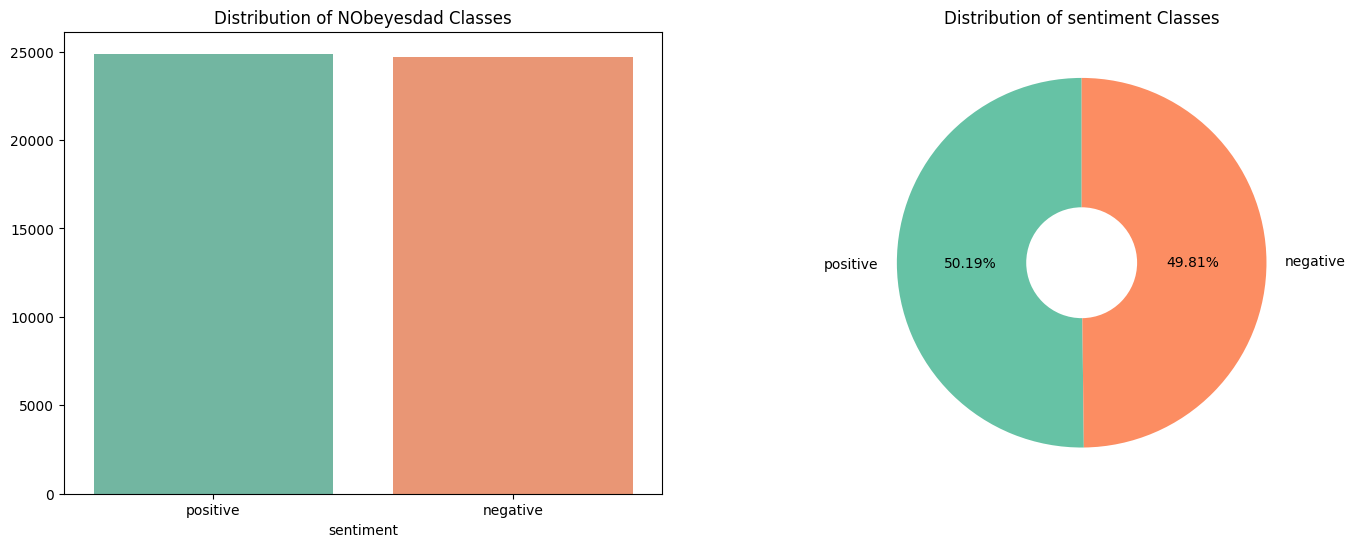

Epoch 1/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 29s 54ms/step - accuracy: 0.8080 - loss: 0.4132 - val_accuracy: 0.8550 - val_loss: 0.3295
Epoch 2/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 26s 52ms/step - accuracy: 0.8806 - loss: 0.2865 - val_accuracy: 0.8571 - val_loss: 0.3289
Epoch 3/3
 78/496 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - accuracy: 0.8996 - loss: 0.2462

In [ ]:
# Load dataset
df = pd.read_csv(
    '/content/IMDB Dataset.csv',
    engine='python',
    on_bad_lines='skip'
)

# Remove duplicates
df.drop_duplicates(inplace=True)

# Plot sentiment distribution
plt.figure(figsize=(17, 6))
counts = df['sentiment'].value_counts()

plt.subplot(1, 2, 1)
sns.barplot(x=counts.index, y=counts.values, palette='Set2')
plt.title("Distribution of NObeyesdad Classes")

plt.subplot(1, 2, 2)
plt.pie(counts, labels=counts.index, autopct='%.2f%%',
        colors=sns.color_palette('Set2', 2), startangle=90,
        wedgeprops={'width': 0.7})
plt.title("Distribution of sentiment Classes")

plt.show()

# Convert sentiment into numbers
y = df['sentiment'].map({'positive': 1, 'negative': 0})
X = df['review']

# Tokenize and pad reviews
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(X)
X = pad_sequences(tokenizer.texts_to_sequences(X), maxlen=100)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Build LSTM model
model = Sequential([
    Embedding(5000, 32),
    LSTM(32),
    Dense(1, activation='sigmoid')
])

# Compile and train
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)